# Fakeddit EDA
Only verified, decodable image-text pairs are included.

,final_split,normalized_label,pairs
0,test,fake,382
1,test,true,565
2,train,fake,1199
3,train,true,1154
4,validate,fake,377
5,validate,true,556


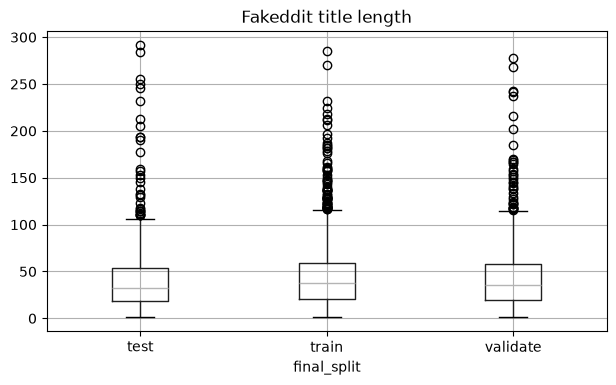

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
root = Path('../data/research_dataset')
m = pd.read_parquet(root / 'manifests/unified_manifest.parquet')
f = m.query("source_dataset == 'Fakeddit' and download_status == 'verified_reused_or_processed'").copy()
f['text_length'] = f.text.str.len()
display(f.groupby(['final_split', 'normalized_label']).size().rename('pairs').reset_index())
f.boxplot(column='text_length', by='final_split', figsize=(7,4)); plt.suptitle(''); plt.title('Fakeddit title length'); plt.show()

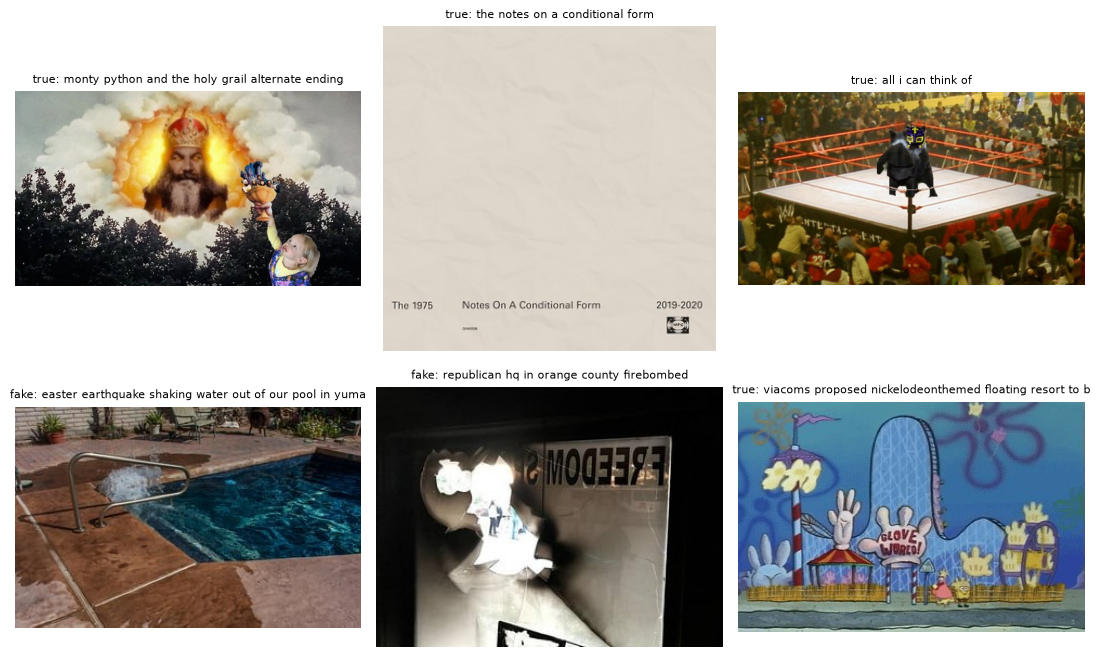

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, (_, row) in zip(axes.ravel(), f.sample(min(6, len(f)), random_state=42).iterrows()):
    ax.imshow(Image.open(root / row.image_path).convert('RGB'))
    ax.set_title(f"{row.normalized_label}: {row.text[:55]}", fontsize=8)
    ax.axis('off')
plt.tight_layout(); plt.show()